# NetSpectre model report
Held-out temporal test split of CICIDS2017 (lab data, not live traffic). Run all cells from top to bottom.

In [8]:

import json, os, numpy as np, pandas as pd, onnxruntime as ort
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             precision_recall_fscore_support, confusion_matrix, roc_auc_score)
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 100)

F = json.load(open("models/feature_cols_35.json"))
cl = json.load(open("models/classes.json"))
names = list(cl) if isinstance(cl, list) else [cl[k] for k in sorted(cl, key=int)]
te = pd.read_parquet("data/processed/test_temporal2.parquet")
X = te[F].to_numpy(dtype="float32"); y = te["Label"].to_numpy()
print(len(te), "flows,", len(F), "features,", len(names), "classes")
print(pd.Series(y).value_counts())

def probs(sess, x):
    p = sess.run(None, {sess.get_inputs()[0].name: x})[1]
    if isinstance(p, list) and isinstance(p[0], dict):
        p = [[d[k] for k in sorted(d, key=int)] for d in p]
    return np.asarray(p, dtype=np.float64)

sx = ort.InferenceSession("models/multiclass_xgb35.onnx")
sc = ort.InferenceSession("models/multiclass_cat35.onnx")
px, pc = [], []
for i in range(0, len(X), 50000):
    b = X[i:i+50000]; px.append(probs(sx, b)); pc.append(probs(sc, b))
px, pc = np.vstack(px), np.vstack(pc); pe = (px + pc) / 2
P = {"XGBoost": px, "CatBoost": pc, "Ensemble": pe}
PRED = {k: np.array(names)[v.argmax(1)] for k, v in P.items()}

meta = json.load(open("models/ae35_meta.json"))
mu, sd = np.array(meta["mu"], dtype=np.float32), np.array(meta["sd"], dtype=np.float32)
ae = ort.InferenceSession("models/ae35.onnx")
sco = []
for i in range(0, len(X), 50000):
    b = X[i:i+50000]
    z = (((np.sign(b) * np.log1p(np.abs(b))).astype(np.float32) - mu) / sd).astype(np.float32)
    r = ae.run(None, {"x": z})[0]; sco.append(((r - z) ** 2).mean(axis=1))
S = np.concatenate(sco)
labs = [c for c in names if c in set(y)]
print("models scored. classes present in test:", len(labs))


499605 flows, 35 features, 15 classes
BENIGN                        414453
DoS Hulk                       34570
DDoS                           25603
PortScan                       18139
DoS GoldenEye                   2057
FTP-Patator                     1187
DoS slowloris                   1075
DoS Slowhttptest                1046
SSH-Patator                      644
Bot                              390
Web Attack - Brute Force         294
Web Attack - XSS                 131
Infiltration                       8
Web Attack - Sql Injection         5
Heartbleed                         3
Name: count, dtype: int64
models scored. classes present in test: 15


## 1. Overall scores per model

In [2]:

rows = []
for k, pr in PRED.items():
    rows.append({"model": k, "accuracy": accuracy_score(y, pr),
                 "macro_precision": precision_score(y, pr, labels=labs, average="macro", zero_division=0),
                 "macro_recall": recall_score(y, pr, labels=labs, average="macro", zero_division=0),
                 "macro_F1": f1_score(y, pr, labels=labs, average="macro", zero_division=0),
                 "weighted_F1": f1_score(y, pr, labels=labs, average="weighted", zero_division=0)})
overall = pd.DataFrame(rows).set_index("model").round(4)
overall


,accuracy,macro_precision,macro_recall,macro_F1,weighted_F1
model,,,,,
XGBoost,0.9940,0.8064,0.9297,0.8523,0.9943
CatBoost,0.9890,0.7167,0.9078,0.7528,0.9899
Ensemble,0.9945,0.8022,0.9304,0.8464,0.9948


## 2. Per-class F1, precision and recall

,XGBoost,CatBoost,Ensemble,support
Web Attack - XSS,0.356,0.351,0.369,131
Bot,0.667,0.380,0.612,390
Web Attack - Brute Force,0.568,0.596,0.616,294
Web Attack - Sql Injection,0.714,0.143,0.625,5
Infiltration,0.762,0.533,0.762,8
DoS slowloris,0.906,0.703,0.908,1075
DoS Slowhttptest,0.923,0.755,0.917,1046
DoS GoldenEye,0.963,0.957,0.964,2057
SSH-Patator,0.995,0.958,0.975,644
DoS Hulk,0.970,0.958,0.976,34570


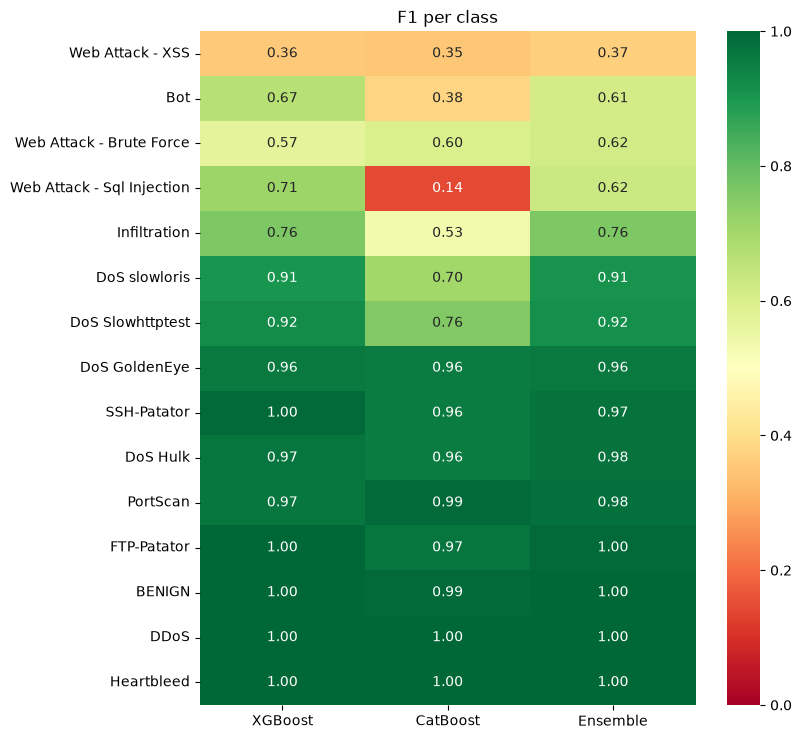

In [3]:

sup = pd.Series(y).value_counts()
f1t = pd.DataFrame(index=labs); rect = pd.DataFrame(index=labs); pret = pd.DataFrame(index=labs)
for k, pr in PRED.items():
    p, r, f, _ = precision_recall_fscore_support(y, pr, labels=labs, zero_division=0)
    f1t[k] = f; rect[k] = r; pret[k] = p
f1t["support"] = [sup[c] for c in labs]
display(f1t.round(3).sort_values("Ensemble"))
plt.figure(figsize=(8, 0.45 * len(labs) + 2))
sns.heatmap(f1t.drop(columns="support").loc[f1t.sort_values("Ensemble").index], annot=True, fmt=".2f",
            cmap="RdYlGn", vmin=0, vmax=1)
plt.title("F1 per class"); plt.show()


## 3. Ensemble confusion matrix (row = true class)

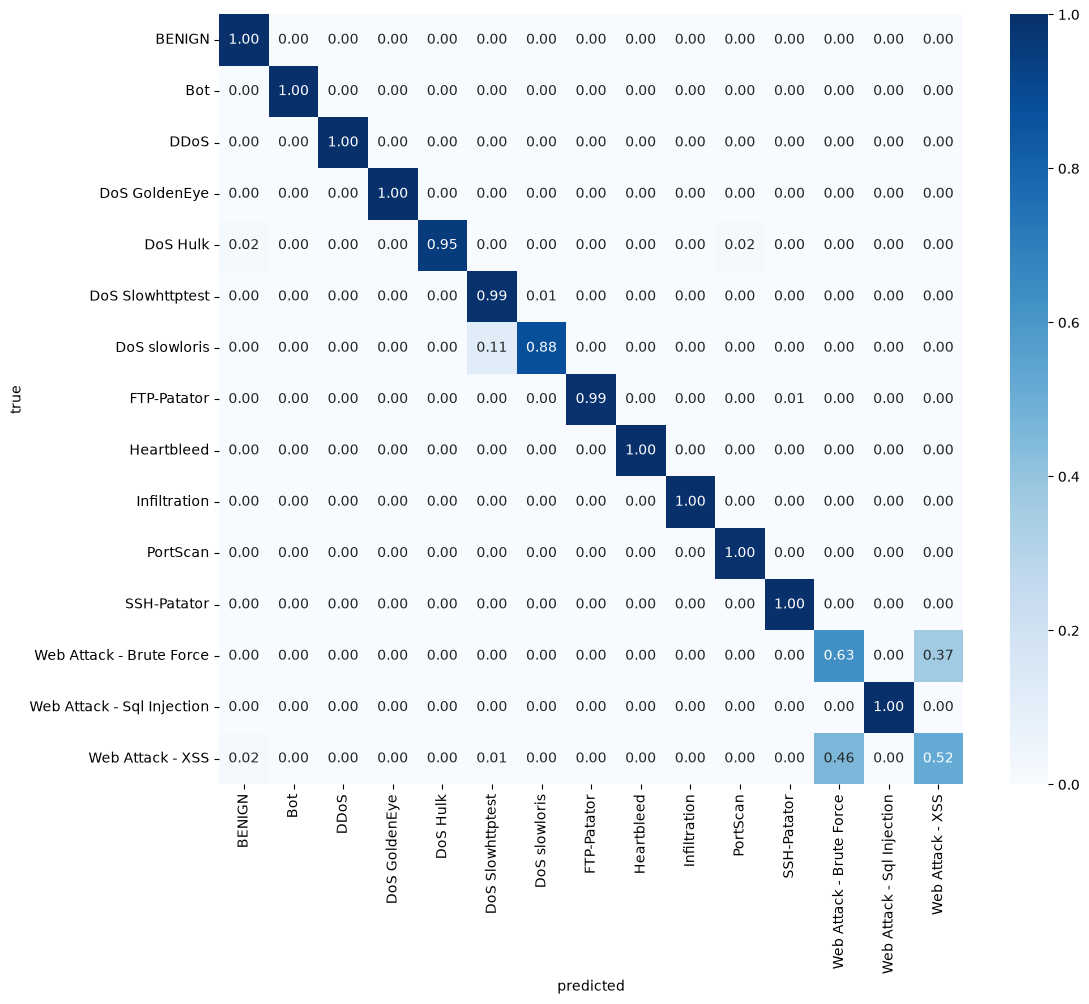

,true,predicted as,flows
0,DoS Hulk,BENIGN,665
1,DoS Hulk,PortScan,616
2,BENIGN,Bot,494
3,DoS Hulk,DoS GoldenEye,142
4,DoS slowloris,DoS Slowhttptest,122
5,Web Attack - Brute Force,Web Attack - XSS,109
6,BENIGN,DoS Hulk,64
7,PortScan,BENIGN,63
8,Web Attack - XSS,Web Attack - Brute Force,60
9,DoS Hulk,Web Attack - Brute Force,48


In [10]:

cm = confusion_matrix(y, PRED["Ensemble"], labels=labs, normalize="true")
plt.figure(figsize=(12, 10))
sns.heatmap(cm, xticklabels=labs, yticklabels=labs, cmap="Blues", annot=len(labs) <= 16, fmt=".2f")
plt.xlabel("predicted"); plt.ylabel("true"); plt.show()
cc = confusion_matrix(y, PRED["Ensemble"], labels=labs)
pairs = [(labs[i], labs[j], int(cc[i, j])) for i in range(len(labs)) for j in range(len(labs)) if i != j and cc[i, j] > 0]
pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:15], columns=["true", "predicted as", "flows"])


## 4. Autoencoder (anomaly detector)
Threshold 0.2369 is the one used by the live monitor (NS_AE_THRESHOLD default).

In [5]:

THR = 0.2369
BEN = "BENIGN"
isb = (y == BEN)
print("benign false-positive rate at threshold:", round(float((S[isb] > THR).mean()), 4), "of", int(isb.sum()), "benign flows")
rows = []
for c in labs:
    if c == BEN: continue
    m = (y == c)
    auc = roc_auc_score(np.r_[np.zeros(isb.sum()), np.ones(m.sum())], np.r_[S[isb], S[m]])
    rows.append({"class": c, "flows": int(m.sum()), "AE detection rate": float((S[m] > THR).mean()),
                 "median score": float(np.median(S[m])), "AUC vs benign": auc})
aedf = pd.DataFrame(rows).set_index("class").round(3).sort_values("AE detection rate")
display(aedf)


benign false-positive rate at threshold: 0.01 of 414453 benign flows


,flows,AE detection rate,median score,AUC vs benign
class,,,,
Bot,390,0.000,0.108,0.954
Heartbleed,3,0.000,0.198,0.984
Web Attack - Brute Force,294,0.000,0.036,0.791
Infiltration,8,0.000,0.127,0.967
Web Attack - Sql Injection,5,0.000,0.088,0.892
Web Attack - XSS,131,0.000,0.036,0.786
SSH-Patator,644,0.002,0.066,0.886
PortScan,18139,0.011,0.099,0.892
FTP-Patator,1187,0.025,0.166,0.980


## 5. What needs improving
A class is flagged WEAK if the ensemble F1 is below 0.80. The last column says whether the autoencoder at least catches it.

In [9]:

t = pd.DataFrame({"support": f1t["support"], "ens_precision": pret["Ensemble"], "ens_recall": rect["Ensemble"], "ens_F1": f1t["Ensemble"]})
t = t.join(aedf[["AE detection rate"]])
t["status"] = np.where(t["ens_F1"] < 0.80, "WEAK", "ok")
t["AE covers it (>=50%)"] = np.where(t["AE detection rate"] >= 0.5, "yes", np.where(t["AE detection rate"].isna(), "-", "no"))
t.round(3).sort_values("ens_F1")


,support,ens_precision,ens_recall,ens_F1,AE detection rate,status,AE covers it (>=50%)
Web Attack - XSS,131,0.286,0.519,0.369,0.000,WEAK,no
Bot,390,0.441,1.000,0.612,0.000,WEAK,no
Web Attack - Brute Force,294,0.603,0.629,0.616,0.000,WEAK,no
Web Attack - Sql Injection,5,0.455,1.000,0.625,0.000,WEAK,no
Infiltration,8,0.615,1.000,0.762,0.000,WEAK,no
DoS slowloris,1075,0.935,0.882,0.908,0.239,ok,no
DoS Slowhttptest,1046,0.853,0.991,0.917,0.859,ok,yes
DoS GoldenEye,2057,0.932,0.998,0.964,0.087,ok,no
SSH-Patator,644,0.954,0.997,0.975,0.002,ok,no
DoS Hulk,34570,0.998,0.954,0.976,0.057,ok,no


In [11]:
w_mask = lambda a: pd.Series(a).str.startswith("Web Attack").to_numpy()
ym = np.where(w_mask(y), "Web Attack", y)
L = sorted(set(ym))
for k in ["XGBoost", "Ensemble"]:
    pm = np.where(w_mask(PRED[k]), "Web Attack", PRED[k])
    print(k, "| macro F1, web attacks merged:", round(f1_score(ym, pm, labels=L, average="macro", zero_division=0), 4),
          "| Web Attack F1:", round(f1_score(ym, pm, labels=["Web Attack"], average="macro", zero_division=0), 3))
print("\nXGBoost weight -> macro F1")
for w in [0, 0.2, 0.4, 0.5, 0.6, 0.8, 0.9, 1.0]:
    pr = np.array(names)[(w * px + (1 - w) * pc).argmax(1)]
    print(w, round(f1_score(y, pr, labels=labs, average="macro", zero_division=0), 4))

XGBoost | macro F1, web attacks merged: 0.9209 | Web Attack F1: 0.824
Ensemble | macro F1, web attacks merged: 0.9194 | Web Attack F1: 0.866

XGBoost weight -> macro F1
0 0.7528
0.2 0.7925
0.4 0.8283
0.5 0.8464
0.6 0.8489
0.8 0.8535
0.9 0.8533
1.0 0.8523
